In [3]:
# ============================================================
#  Cell 1 — environment + physical constants (v2, Br8667)
#  Reproduces STalign Fig. 3: cross-technology expression
#  correspondence, Xenium (source) -> Visium (target).
# ============================================================
import os, glob, re, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

import scanpy as sc
import anndata as ad
from scipy.io import mmread
from scipy.spatial import cKDTree
from scipy.stats import spearmanr, mannwhitneyu

from STalign import STalign

# ---- device: STalign builds tensors on the default device ----
device = "cuda:0" if torch.cuda.is_available() else "cpu"
torch.set_default_device(device)

# ---- silence known-harmless warnings seen in this pipeline ----
for msg in (".*match groups.*", ".*To copy construct.*",
            ".*no positive values.*", ".*meshgrid.*"):
    warnings.filterwarnings("ignore", message=msg)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 600,
                     "axes.grid": False, "font.size": 10})

# ============================================================
#  Physical scale — verified constants (not section-specific fits)
#  Xenium: cell_feature_matrix / transcripts coords are ALREADY µm.
#  Visium: coords are full-res pixels; the only reliable ruler is
#          the fixed 100 µm spot pitch, so µm/px is back-computed
#          from it — never the 0.73 in some sections' scalefactors.
# ============================================================
XEN_PX_UM  = 0.2125      # Xenium full-res image px (only for overlaying morphology.tif)
SPOT_DIAM  = 55.0        # Visium spot diameter (µm), fixed
SPOT_PITCH = 100.0       # Visium spot centre-to-centre (µm), fixed -> scale anchor

DX_SOURCE, DX_TARGET = 30.0, 100.0   # µm grid (Xenium) / px grid (Visium)
DTYPE = torch.float64
MATCH_THRESH = 0.85
GRID_UM = 200.0                       # expression-correspondence pixel size (paper)

SPD_ORDER  = ["SpD07-L1", "SpD06-L2/3", "SpD02-L3/4",
              "SpD05-L5", "SpD03-L6", "SpD04-WM", "SpD01-WMtz"]
MARK_UPPER = ["CUX2", "LAMP5", "RORB"]
MARK_WM    = ["MBP", "PLP1", "MOBP", "MOG", "CLDN11"]

# ============================================================
#  Sample + paths  (v2: Br8667)
# ============================================================
SAMPLE = "Br8667"
XDIR   = "/home/yf23c/Guo_xenium/xenium"
VDIR   = f"/home/yf23c/Guo_xenium/{SAMPLE}_export"
OUT    = f"/home/yf23c/Guo_xenium/stalign_out/{SAMPLE}"; os.makedirs(OUT, exist_ok=True)

# --- full Xenium donor list (cells file may be .parquet OR .parquet.gz) ---
allcells = (glob.glob(f"{XDIR}/*-cells.parquet") +
            glob.glob(f"{XDIR}/*-cells.parquet.gz"))
xn = sorted({re.search(r"_(Br\d+)-cells", os.path.basename(p)).group(1) for p in allcells})
print(f"Xenium donors ({len(xn)}): {xn}")

# --- resolve this sample's stem, keep the real cells path (may be .gz) ---
hits = (glob.glob(f"{XDIR}/GSM*_{SAMPLE}-cells.parquet") +
        glob.glob(f"{XDIR}/GSM*_{SAMPLE}-cells.parquet.gz"))
assert len(hits) >= 1, f"no Xenium cells file for {SAMPLE}: {hits}"
CELLS_PATH = hits[0]
XSTEM = CELLS_PATH.replace("-cells.parquet.gz", "").replace("-cells.parquet", "")

print(f"\nsample : {SAMPLE}")
print(f"device : {device}"
      f"{' — ' + torch.cuda.get_device_name(0) if torch.cuda.is_available() else ''}")
print(f"Xenium : {os.path.basename(XSTEM)}")
print(f"cells  : {os.path.basename(CELLS_PATH)}")
need = {"mtx": f"{XSTEM}-cell_feature_matrix.h5",
        "vis counts": f"{VDIR}/{SAMPLE}_counts.mtx",
        "vis coords": f"{VDIR}/{SAMPLE}_coordinates.csv",
        "vis meta":   f"{VDIR}/{SAMPLE}_metadata.csv",
        "vis genes":  f"{VDIR}/{SAMPLE}_gene_annotation.csv"}
print(f"  {'OK ':8s} cells       {os.path.basename(CELLS_PATH)}")
for k, p in need.items():
    print(f"  {'OK ' if os.path.exists(p) else 'MISSING':8s} {k:11s} {os.path.basename(p)}")

Xenium donors (24): ['Br1113', 'Br1139', 'Br2039', 'Br2421', 'Br2719', 'Br5314', 'Br5373', 'Br5400', 'Br5436', 'Br5588', 'Br5590', 'Br5622', 'Br5639', 'Br5746', 'Br5931', 'Br5973', 'Br6032', 'Br6389', 'Br6432', 'Br6437', 'Br6496', 'Br8433', 'Br8667', 'Br8772']

sample : Br8667
device : cuda:0 — NVIDIA GeForce GTX 1080
Xenium : GSM9223485_Br8667
cells  : GSM9223485_Br8667-cells.parquet.gz
  OK       cells       GSM9223485_Br8667-cells.parquet.gz
  OK       mtx         GSM9223485_Br8667-cell_feature_matrix.h5
  OK       vis counts  Br8667_counts.mtx
  OK       vis coords  Br8667_coordinates.csv
  OK       vis meta    Br8667_metadata.csv
  OK       vis genes   Br8667_gene_annotation.csv


In [16]:
# ============================================================
#  Cell 2 — load Xenium + Visium, QC (flag), scale check (v2, Br8667)
#  Xenium cells FLAGGED not dropped. Original cells-file row index is
#  preserved in obs['orig_row'] so Lieber's Br####_<rowidx> annotation
#  keys can be joined later (their key = 1-based row in the cells file).
# ============================================================
import gzip, io

# ---------------- Xenium: centroids + 300-gene panel ----------------
def read_parquet_any(path):
    with open(path, "rb") as f:
        is_gz = f.read(2) == b"\x1f\x8b"
    if is_gz:
        with gzip.open(path, "rb") as f:
            return pd.read_parquet(io.BytesIO(f.read()))
    return pd.read_parquet(path)

cells = read_parquet_any(CELLS_PATH)
cells = cells.reset_index(drop=True)                    # ensure 0..N-1 positional index
cells["orig_row"] = np.arange(len(cells)) + 1           # 1-based, matches Lieber's key suffix

adata = sc.read_10x_h5(f"{XSTEM}-cell_feature_matrix.h5"); adata.var_names_make_unique()
adata = adata[cells["cell_id"].astype(str).values].copy()
adata.obsm["spatial"]   = cells[["x_centroid", "y_centroid"]].to_numpy(float)
adata.obs["orig_row"]   = cells["orig_row"].values      # carry the original row number
adata.obs["cell_id_xe"] = cells["cell_id"].astype(str).values
for c in ("cell_area", "nucleus_area"):
    if c in cells: adata.obs[c] = cells[c].to_numpy()

is_ctrl = adata.var_names.str.match(
    r"^(NegControlProbe|NegControlCodeword|Unassigned|BLANK|Deprecated|Intergenic)", case=False)

# QC on all features; drop empty cells (orig_row stays attached to survivors)
X = adata.X.toarray() if hasattr(adata.X, "toarray") else np.asarray(adata.X)
nonempty = X.sum(1) > 0
adata, X = adata[nonempty].copy(), X[nonempty]
def mad_out(v, t="both", n=3):
    v = np.asarray(v, float); m = np.median(v); s = np.median(np.abs(v - m)) * 1.4826
    return {"lower": v < m-n*s, "both": (v < m-n*s) | (v > m+n*s)}[t]
adata.obs["total_counts"] = X.sum(1)
adata.obs["detected"]     = (X > 0).sum(1)
adata.obs["is_outlier"]   = mad_out(X.sum(1), "both") | mad_out((X > 0).sum(1), "lower")
adata = adata[:, ~is_ctrl].copy()
xI, yI = adata.obsm["spatial"].T

# ---------------- Visium: flat SPE export ----------------
rl = lambda p: [l.strip().strip('"') for l in open(p) if l.strip()]
bc, gn = rl(f"{VDIR}/{SAMPLE}_barcodes.tsv"), rl(f"{VDIR}/{SAMPLE}_genes.tsv")
orient = lambda M: (M.T if M.shape == (len(gn), len(bc)) else M).tocsr()   # -> spots x genes
vadata = ad.AnnData(X=orient(mmread(f"{VDIR}/{SAMPLE}_counts.mtx").tocsr()))
if os.path.exists(f"{VDIR}/{SAMPLE}_logcounts.mtx"):
    vadata.layers["logcounts"] = orient(mmread(f"{VDIR}/{SAMPLE}_logcounts.mtx").tocsr())
vadata.obs_names, vadata.var_names = bc, gn

vadata.obs = vadata.obs.join(pd.read_csv(f"{VDIR}/{SAMPLE}_metadata.csv").set_index("barcode"))
coord = pd.read_csv(f"{VDIR}/{SAMPLE}_coordinates.csv").set_index("barcode")
vadata.obsm["spatial"] = coord.loc[bc, ["x", "y"]].to_numpy(float)          # full-res pixels

gann = pd.read_csv(f"{VDIR}/{SAMPLE}_gene_annotation.csv").drop_duplicates("gene_id").set_index("gene_id")
mapped = vadata.var_names.map(gann["gene_name"])
vadata.var["gene_id"] = vadata.var_names.values
vadata.var_names = np.where(mapped.notna(), mapped, vadata.var_names)
vadata.var_names_make_unique()
xJ, yJ = vadata.obsm["spatial"].T

# ---------------- scale: Xenium µm; Visium via fixed 100 µm pitch ----------------
pitch_px  = np.median(cKDTree(np.c_[xJ, yJ]).query(np.c_[xJ, yJ], k=2)[0][:, 1])
PX_PER_UM = pitch_px / SPOT_PITCH
UM_PER_PX = SPOT_PITCH / pitch_px
SPOT_R_PX = pitch_px * SPOT_DIAM / SPOT_PITCH / 2

shared = sorted(set(adata.var_names) & set(vadata.var_names))
xJ_um, yJ_um = xJ * UM_PER_PX, yJ * UM_PER_PX
dx = vadata.obs["DX"].unique()[0] if "DX" in vadata.obs else "?"

# ---------------- summary ----------------
print(f"Xenium : {adata.n_obs:>6} cells x {adata.n_vars} genes | "
      f"{xI.ptp()/1000:.1f} x {yI.ptp()/1000:.1f} mm | flagged {adata.obs.is_outlier.mean()*100:.1f}%")
print(f"Visium : {vadata.n_obs:>6} spots x {vadata.n_vars} genes | "
      f"{xJ_um.ptp()/1000:.1f} x {yJ_um.ptp()/1000:.1f} mm | dx {dx}")
print(f"scale  : pitch {pitch_px:.1f} px = 100 µm -> {UM_PER_PX:.4f} µm/px | spot R {SPOT_R_PX:.1f} px")
print(f"shared : {len(shared)} genes")

# ---------------- self-check ----------------
chk = {
    "shared == 300":                 len(shared) == 300,
    "Xenium wider than Visium (µm)": xI.ptp() > xJ_um.ptp(),
    "Xenium mm in 2-15":             2 < xI.ptp()/1000 < 15,
    "Visium mm in 2-15":             2 < xJ_um.ptp()/1000 < 15,
    "um/px in 0.3-1.0":              0.3 < UM_PER_PX < 1.0,
    "dx present":                    dx != "?",
    "flagged < 15%":                 adata.obs.is_outlier.mean() < 0.15,
    "orig_row present":              "orig_row" in adata.obs,
}
print("\n--- self-check ---")
for k, v in chk.items(): print(f"  [{'PASS' if v else 'CHECK'}] {k}")
print("ALL PASS" if all(chk.values()) else ">>> some CHECK <<<")

Xenium :  68974 cells x 300 genes | 10.2 x 7.2 mm | flagged 1.2%
Visium :   4800 spots x 36601 genes | 6.4 x 6.7 mm | dx NTC
scale  : pitch 201.0 px = 100 µm -> 0.4975 µm/px | spot R 55.3 px
shared : 300 genes

--- self-check ---
  [PASS] shared == 300
  [PASS] Xenium wider than Visium (µm)
  [PASS] Xenium mm in 2-15
  [PASS] Visium mm in 2-15
  [PASS] um/px in 0.3-1.0
  [PASS] dx present
  [PASS] flagged < 15%
  [PASS] orig_row present
ALL PASS


keys present in Lieber annotation: 95.9%  (missing = their QC outliers)
layer coverage 95.9% | cell-type coverage 95.9%

layer counts:
 layer
L5      20280
L2/3    16405
WM      12303
L1/M     7177
L6       5948
NaN      2810
L3/4     2276
WMtz     1775
Name: count, dtype: int64

cell-type counts:
 cell_type
Oligo            14701
Endo             13821
Ast               9247
L2/3 Ex           7312
Mic               4577
In: SST,PVALB     3770
L4/5 Ex           3287
In: VIP,LAMP5     2932
NaN               2810
Ambig/In/Endo     2564
L6 Ex             2383
Ambig/Oligo       1284
L5 Ex              286
Name: count, dtype: int64


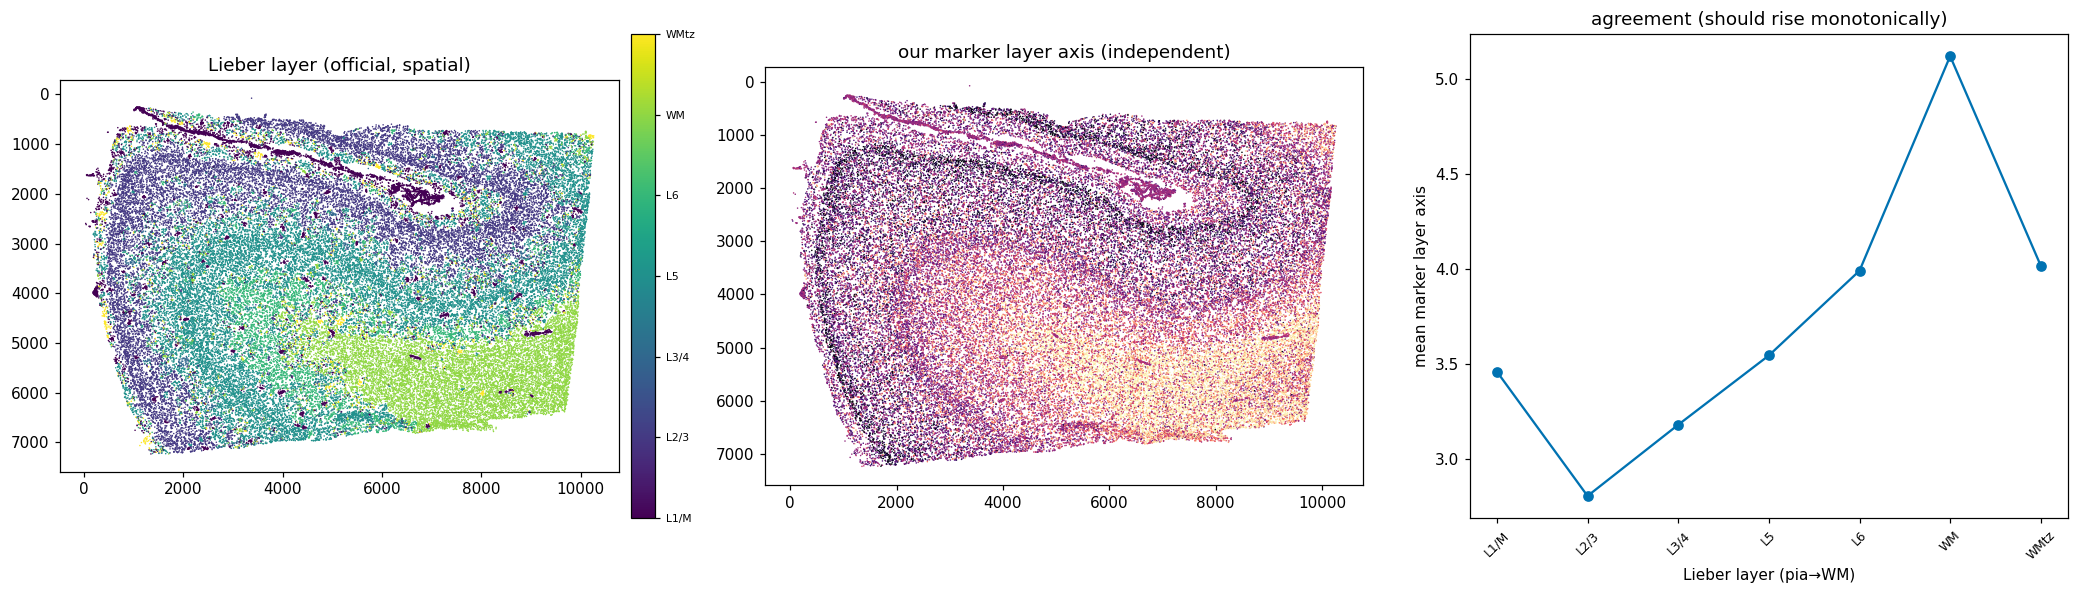


[PASS] layer-axis agreement: Spearman(Lieber layer order, our axis) = 0.857
     high positive => keys aligned correctly; near 0 => misaligned


In [17]:
# ============================================================
#  Cell 2b — attach Lieber official annotations to adata (Br8667)
#  Key = f"{BrNum}_{orig_row}", where orig_row is the 1-based row in
#  the cells file (== how 01_build_spe.R named columns). Annotation
#  CSVs exclude Lieber's QC outliers, so missing keys -> NA.
#  Ref: cindyfang70, issue #1; merge scripts 04_.../02 and 07_.../01.
# ============================================================
BASE = ("https://raw.githubusercontent.com/LieberInstitute/"
        "spatialDLPFC_SCZ_XENIUM/devel/processed-data")

# ---- domain / layer labels (NMF label transfer + smoothing) ----
spd = pd.read_csv(f"{BASE}/04_label_transfer/label_transfer_N24_k50_smoothed_labels.csv")
spd.columns = ["key", "predictions_smooth"]
spd = spd.set_index("key")["predictions_smooth"]

# ---- cell-type clusters (BANKSY lambda=0.1 res=0.7) ----
ct = pd.read_csv(f"{BASE}/06_cell_type_clustering/banksy_clustering_lambda0.1_res0.7.csv")
ct = ct.set_index("V2")["V1"]                          # V2 = key, V1 = cluster id

# ---- official mapping tables (verbatim from the merge scripts) ----
DOMAIN2LAYER = {"spd07": "L1/M", "spd06": "L2/3", "spd02": "L3/4", "spd05": "L5",
                "spd03": "L6", "spd04": "WM", "spd01": "WMtz"}
CLUSTER2CT = {2: "L2/3 Ex", 11: "L4/5 Ex", 18: "L5 Ex", 14: "L6 Ex",
              9: "In: SST,PVALB", 12: "In: VIP,LAMP5",
              6: "Oligo", 8: "Oligo", 1: "Oligo", 10: "Ambig/Oligo",
              7: "Mic", 17: "Ast", 16: "Ast", 4: "Ast",
              5: "Endo", 13: "Endo", 3: "Endo", 15: "Ambig/In/Endo"}

# ---- build keys from orig_row and map ----
keys = pd.Series([f"{SAMPLE}_{r}" for r in adata.obs["orig_row"]], index=adata.obs_names)
adata.obs["lieber_key"]   = keys.values
adata.obs["spd"]          = keys.map(spd).values
adata.obs["layer"]        = adata.obs["spd"].map(DOMAIN2LAYER)
adata.obs["banksy_clust"] = keys.map(ct).values
adata.obs["cell_type"]    = adata.obs["banksy_clust"].map(CLUSTER2CT)

# ---- coverage ----
cov_l = adata.obs["layer"].notna().mean()
cov_c = adata.obs["cell_type"].notna().mean()
n_key_exist = keys.isin(spd.index).mean()
print(f"keys present in Lieber annotation: {n_key_exist*100:.1f}%  "
      f"(missing = their QC outliers)")
print(f"layer coverage {cov_l*100:.1f}% | cell-type coverage {cov_c*100:.1f}%")
print("\nlayer counts:\n", adata.obs["layer"].value_counts(dropna=False))
print("\ncell-type counts:\n", adata.obs["cell_type"].value_counts(dropna=False))

# ============================================================
#  Verify the join is CORRECT, not just populated:
#  Lieber's official layer must agree spatially with our
#  independent marker-based layer axis. If keys were misaligned,
#  the official labels would scatter randomly in space.
# ============================================================
lay_order = ["L1/M", "L2/3", "L3/4", "L5", "L6", "WM", "WMtz"]
lay_code  = adata.obs["layer"].map({l: i for i, l in enumerate(lay_order)})
okm = adata.obs["layer"].notna().values

fig, ax = plt.subplots(1, 3, figsize=(19, 5.5))
p = ax[0].scatter(xI[okm], yI[okm], c=lay_code[okm], s=1, cmap="viridis", linewidths=0)
ax[0].set_title("Lieber layer (official, spatial)")
cb = plt.colorbar(p, ax=ax[0], fraction=.046, pad=.02, ticks=range(len(lay_order)))
cb.ax.set_yticklabels(lay_order, fontsize=7)

ax[1].scatter(xI, yI, c=layer_axis, s=1, cmap="magma", linewidths=0,
              vmin=np.percentile(layer_axis, 2), vmax=np.percentile(layer_axis, 98))
ax[1].set_title("our marker layer axis (independent)")

# quantitative: does official layer order track our layer axis?
prof = pd.DataFrame({"lay": lay_code[okm], "ax": layer_axis[okm]}
                    ).groupby("lay", observed=True)["ax"].mean()
ax[2].plot(prof.index, prof.values, "-o", c="#0072B2")
ax[2].set_xticks(range(len(lay_order))); ax[2].set_xticklabels(lay_order, rotation=45, fontsize=8)
ax[2].set_xlabel("Lieber layer (pia→WM)"); ax[2].set_ylabel("mean marker layer axis")
ax[2].set_title("agreement (should rise monotonically)")

for a in ax[:2]: a.set_aspect("equal"); a.invert_yaxis()
plt.tight_layout(); plt.show()

# monotonicity as a hard check
rho = spearmanr(prof.index, prof.values).statistic
print(f"\n[{'PASS' if rho > 0.8 else 'CHECK'}] layer-axis agreement: "
      f"Spearman(Lieber layer order, our axis) = {rho:.3f}")
print("     high positive => keys aligned correctly; near 0 => misaligned")

polarity (top-decile centroids):
  Xenium pia (marker)    x=    4437  y=    2858
  Xenium WM  (marker)    x=    6873  y=    5256
  Xenium WM  (official)  x=    7023  y=    5150
  Visium pia (marker)    x=    8765  y=    7965
  Visium WM  (marker)    x=    5740  y=   12547


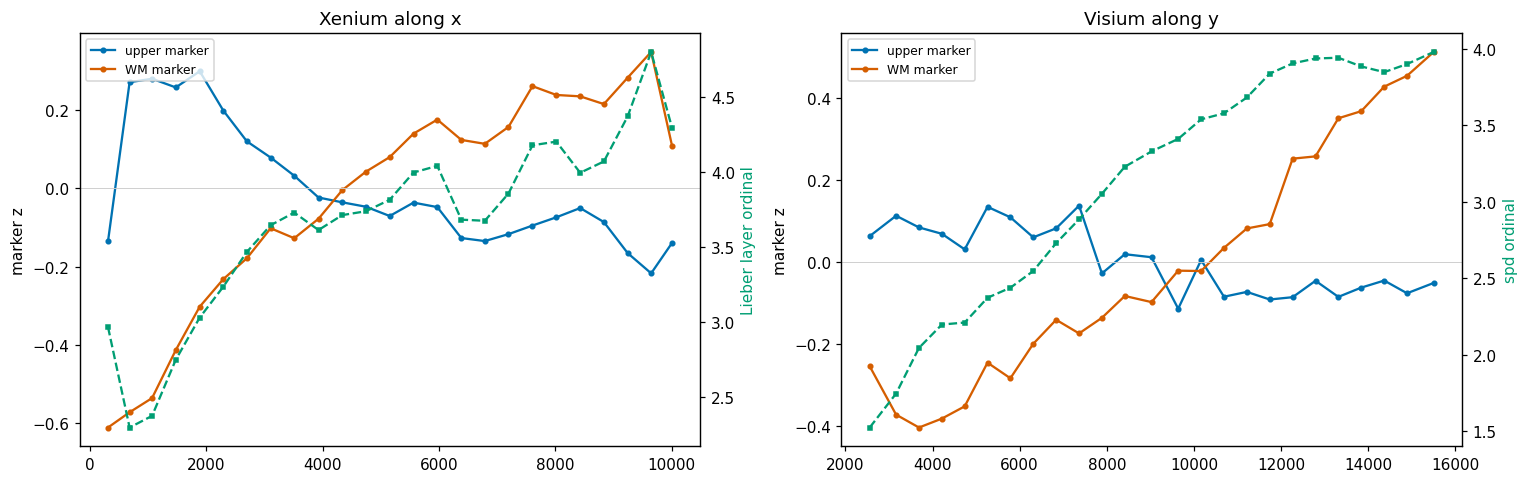

--- self-check ---
  [PASS] spd_label valid
  [PASS] official layer present
  [PASS] Xenium pia≠WM in x (marker)
  [PASS] Visium pia≠WM in y (marker)
  [PASS] layer_axis 1..7
  [PASS] no NaN in layer_axis
ALL PASS


In [18]:
# ============================================================
#  Cell 3 — layer axis + orientation (v2, Br8667)
#  Now uses Lieber's official layer labels (validated ρ=0.857) as the
#  primary pia->WM reference for Xenium, with marker scores as an
#  independent cross-check. Visium uses spd_label. Both modalities'
#  axes must run the same direction before driving a common alignment.
# ============================================================
LAYER_ORDER = ["L1/M", "L2/3", "L3/4", "L5", "L6", "WM", "WMtz"]   # pia -> WM

def marker_score(A, genes, layer=None):
    """Mean z across markers on library-normalised values (raw-count
    z-scoring confounds with total transcripts, which varies pia->WM)."""
    g = [x for x in genes if x in A.var_names]
    M = A[:, g].layers[layer] if layer else A[:, g].X
    M = M.toarray() if hasattr(M, "toarray") else np.asarray(M)
    if layer is None:
        lib = np.asarray(A.X.sum(1)).ravel()[:, None].astype(float); lib[lib == 0] = 1
        M = np.log1p(M / lib * 1e4)
    return ((M - M.mean(0)) / (M.std(0) + 1e-9)).mean(1), g

# ---- marker scores (both modalities) ----
up_s, g_up  = marker_score(adata,  MARK_UPPER)
wm_s, g_wm  = marker_score(adata,  MARK_WM)
up_v, gv_up = marker_score(vadata, MARK_UPPER, layer="logcounts")
wm_v, gv_wm = marker_score(vadata, MARK_WM,    layer="logcounts")

# ---- Visium ordinal from spd_label ----
lab = vadata.obs["spd_label"].map({d: i + 1 for i, d in enumerate(SPD_ORDER)}).to_numpy(float)
spd_ok = not np.isnan(lab).any()

# ---- Xenium layer axis: PRIMARY = Lieber official layer ordinal ----
#      (marker difference kept as an independent continuous fallback)
lay_code = adata.obs["layer"].map({l: i + 1 for i, l in enumerate(LAYER_ORDER)})
has_off  = lay_code.notna().values
layer_axis_marker = wm_s - up_s
layer_axis_marker = layer_axis_marker - layer_axis_marker.min() + 0.1

# use official ordinal where available, marker rank elsewhere (rescaled to match)
from scipy.stats import rankdata
la = np.full(adata.n_obs, np.nan)
la[has_off] = lay_code.values[has_off].astype(float)
# fill the ~4% Lieber outliers with marker-derived ordinal on the same 1..7 scale
if (~has_off).any():
    mk = layer_axis_marker[~has_off]
    la[~has_off] = 1 + 6 * (rankdata(mk) - 1) / (len(mk) - 1)
layer_axis = la  # 1 (pia) .. 7 (WM), official-backed

# ---- polarity by top-decile centroid (official layer & markers should agree) ----
def pole(score, x, y, q=0.90):
    m = score >= np.nanquantile(score, q); return x[m].mean(), y[m].mean()
poles = {
    "Xenium pia (marker)":   pole(up_s, xI, yI),
    "Xenium WM  (marker)":   pole(wm_s, xI, yI),
    "Xenium WM  (official)": pole(np.where(has_off, la, np.nan), xI, yI),
    "Visium pia (marker)":   pole(up_v, xJ, yJ),
    "Visium WM  (marker)":   pole(wm_v, xJ, yJ),
}
print("polarity (top-decile centroids):")
for nm, (px, py) in poles.items():
    print(f"  {nm:22s} x={px:8.0f}  y={py:8.0f}")

# ---- 1-D profiles: Xenium official layer vs Visium spd, both pia->WM ----
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
# Xenium: official layer ordinal along x + marker curves
b = pd.cut(xI, 25)
dfx = pd.DataFrame({"c": xI, "u": up_s, "w": wm_s,
                    "off": np.where(has_off, la, np.nan), "b": b}).groupby("b", observed=True)
mid = dfx["c"].mean()
ax[0].plot(mid, dfx["u"].mean(), "-o", ms=3, c="#0072B2", label="upper marker")
ax[0].plot(mid, dfx["w"].mean(), "-o", ms=3, c="#D55E00", label="WM marker")
a0 = ax[0].twinx()
a0.plot(mid, dfx["off"].mean(), "--s", ms=3, c="#009E73", label="Lieber layer")
a0.set_ylabel("Lieber layer ordinal", color="#009E73")
ax[0].set_title("Xenium along x"); ax[0].set_ylabel("marker z"); ax[0].axhline(0, c="#ccc", lw=.6)
ax[0].legend(fontsize=8, loc="upper left")

# Visium: spd ordinal along y + marker curves
b = pd.cut(yJ, 25)
dfv = pd.DataFrame({"c": yJ, "u": up_v, "w": wm_v, "l": lab, "b": b}).groupby("b", observed=True)
mid = dfv["c"].mean()
ax[1].plot(mid, dfv["u"].mean(), "-o", ms=3, c="#0072B2", label="upper marker")
ax[1].plot(mid, dfv["w"].mean(), "-o", ms=3, c="#D55E00", label="WM marker")
a1 = ax[1].twinx()
a1.plot(mid, dfv["l"].mean(), "--s", ms=3, c="#009E73", label="spd ordinal")
a1.set_ylabel("spd ordinal", color="#009E73")
ax[1].set_title("Visium along y"); ax[1].set_ylabel("marker z"); ax[1].axhline(0, c="#ccc", lw=.6)
ax[1].legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

# ---- self-check ----
chk = {
    "spd_label valid":          spd_ok,
    "official layer present":   has_off.mean() > 0.8,
    "Xenium pia≠WM in x (marker)": abs(poles["Xenium pia (marker)"][0]-poles["Xenium WM  (marker)"][0]) > 500,
    "Visium pia≠WM in y (marker)": abs(poles["Visium pia (marker)"][1]-poles["Visium WM  (marker)"][1]) > 500,
    "layer_axis 1..7":          np.nanmin(layer_axis) >= 1 and np.nanmax(layer_axis) <= 7,
    "no NaN in layer_axis":     not np.isnan(layer_axis).any(),
}
print("--- self-check ---")
for k, v in chk.items(): print(f"  [{'PASS' if v else 'CHECK'}] {k}")
print("ALL PASS" if all(chk.values()) else ">>> some CHECK <<<")

mirror=False det=+4.040  IoU=0.420
mirror=True  det=-4.040  IoU=0.421
IoU favours mirror=True (degenerate — LDDMM decides in Cell 6)


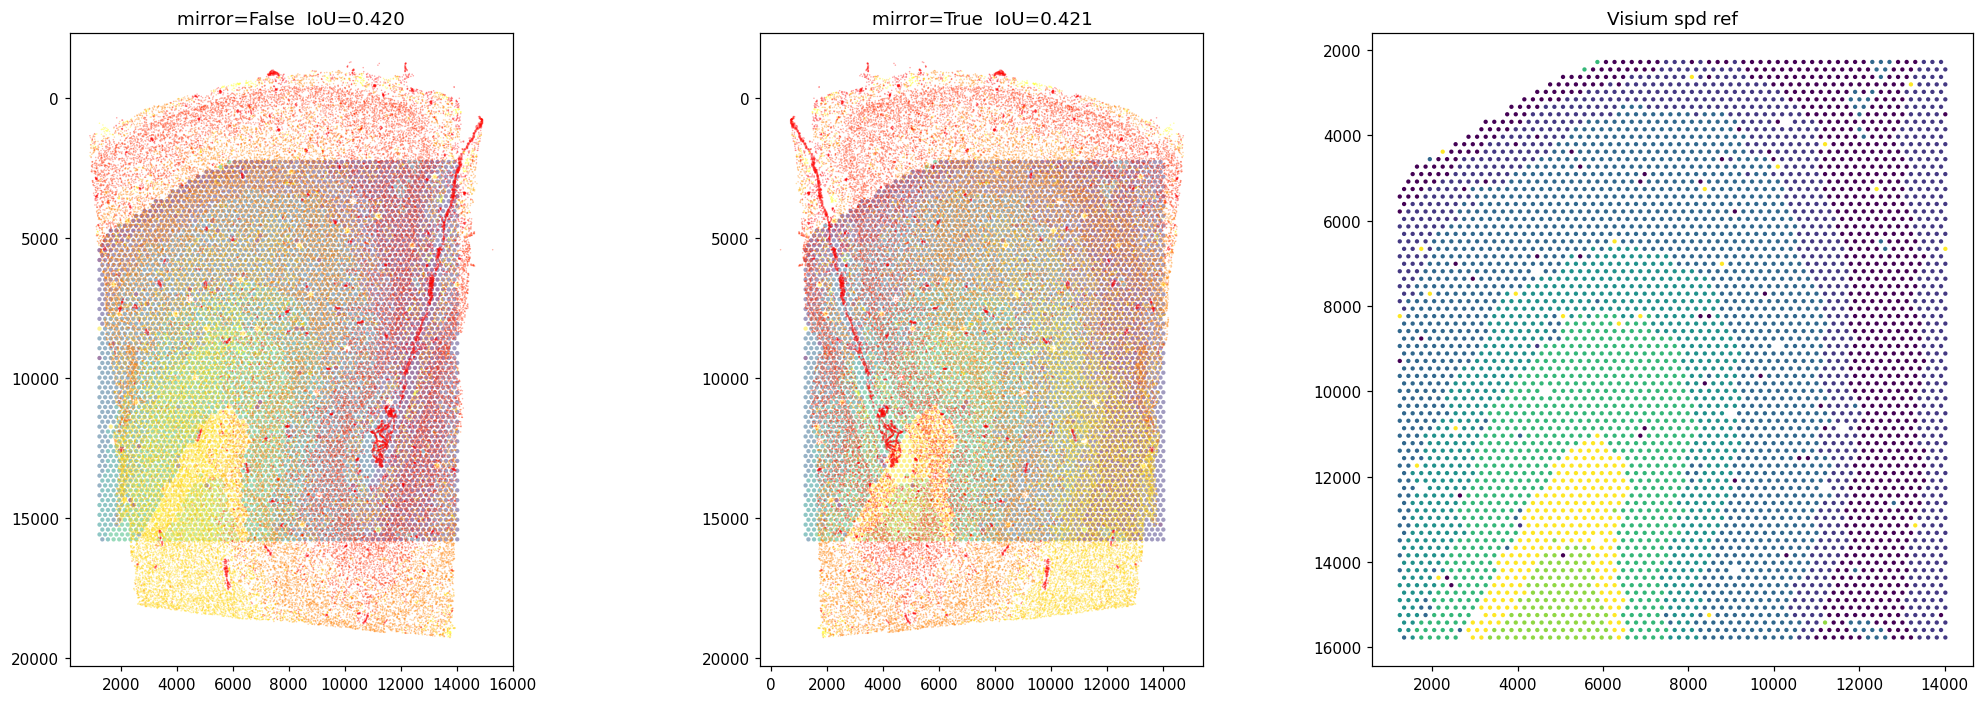

--- self-check ---
  [PASS] rotation = 90°
  [PASS] scale = PX_PER_UM
  [PASS] det sign differs
  [PASS] both A finite
ALL PASS


In [19]:
# ============================================================
#  Cell 4 — initial affine, fixed CCW 90° (v2, Br8667)
#  Scale = physical PX_PER_UM (Visium 100 µm pitch), not a bbox fit.
#  Mirror is chosen by outline IoU; if degenerate (it was: 0.42 vs
#  0.42), both are carried to LDDMM and decided by matched fraction.
# ============================================================
th = np.radians(90)                                        # fixed rotation (Guo)
Rrot = np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])

def build_A(mirror):
    M = Rrot @ np.diag([1, -1]) if mirror else Rrot
    S = PX_PER_UM * M
    src, dst = np.c_[xI, yI], np.c_[xJ, yJ]
    t = dst.mean(0) - (src @ S.T).mean(0)                  # centroid alignment
    A = np.eye(3)                                          # STalign acts on (y, x, 1)
    A[0,0], A[0,1], A[0,2] = S[1,1], S[1,0], t[1]
    A[1,0], A[1,1], A[1,2] = S[0,1], S[0,0], t[0]
    return A, src @ S.T + t

def outline_iou(pts, ref, bs=150.0):
    lo, hi = np.minimum(pts.min(0),ref.min(0)), np.maximum(pts.max(0),ref.max(0))
    bn = [np.arange(lo[i],hi[i]+bs,bs) for i in (0,1)]
    h1, h2 = np.histogram2d(*pts.T,bins=bn)[0]>0, np.histogram2d(*ref.T,bins=bn)[0]>0
    return (h1&h2).sum()/(h1|h2).sum()

ref = np.c_[xJ, yJ]
cands = {m: (*build_A(m),) for m in (False, True)}
cands = {m: (A, out, outline_iou(out, ref)) for m, (A, out) in cands.items()}
for m,(A,_,iou) in cands.items():
    print(f"mirror={str(m):5s} det={np.linalg.det(A[:2,:2]):+.3f}  IoU={iou:.3f}")
MIRROR_INIT = max(cands, key=lambda m: cands[m][2])
print(f"IoU favours mirror={MIRROR_INIT} (degenerate — LDDMM decides in Cell 6)")

# ---- visual: both candidates, Xenium layer axis over Visium spd ----
fig, ax = plt.subplots(1, 3, figsize=(19, 6.5))
for a, m in zip(ax[:2], (False, True)):
    _, out, iou = cands[m]
    a.scatter(xJ, yJ, s=8, c=lab, cmap="viridis", alpha=.5, linewidths=0)
    a.scatter(*out.T, s=1, c=layer_axis, cmap="autumn", alpha=.35, linewidths=0,
              vmin=1, vmax=7)
    a.set_title(f"mirror={m}  IoU={iou:.3f}")
ax[2].scatter(xJ, yJ, s=8, c=lab, cmap="viridis", linewidths=0); ax[2].set_title("Visium spd ref")
for a in ax: a.set_aspect("equal"); a.invert_yaxis()
plt.tight_layout(); plt.show()

# ---- self-check ----
chk = {
    "rotation = 90°":       abs(th - np.radians(90)) < 1e-9,
    "scale = PX_PER_UM":    abs(np.linalg.svd(cands[False][0][:2,:2], compute_uv=False).mean()
                                - PX_PER_UM) < 1e-6,
    "det sign differs":     np.sign(np.linalg.det(cands[False][0][:2,:2])) !=
                            np.sign(np.linalg.det(cands[True][0][:2,:2])),
    "both A finite":        np.isfinite(cands[False][0]).all() and np.isfinite(cands[True][0]).all(),
}
print("--- self-check ---")
for k, v in chk.items(): print(f"  [{'PASS' if v else 'CHECK'}] {k}")
print("ALL PASS" if all(chk.values()) else ">>> some CHECK <<<")

I (3, 263, 376)  grid 263x376  dx=30.0 µm
J (3, 149, 141)  grid 149x141  dx=100.0 px


/tmp/ipykernel_276150/536664091.py:20: RuntimeWarning: Mean of empty slice
  return np.nanmean(m, axis=axis)


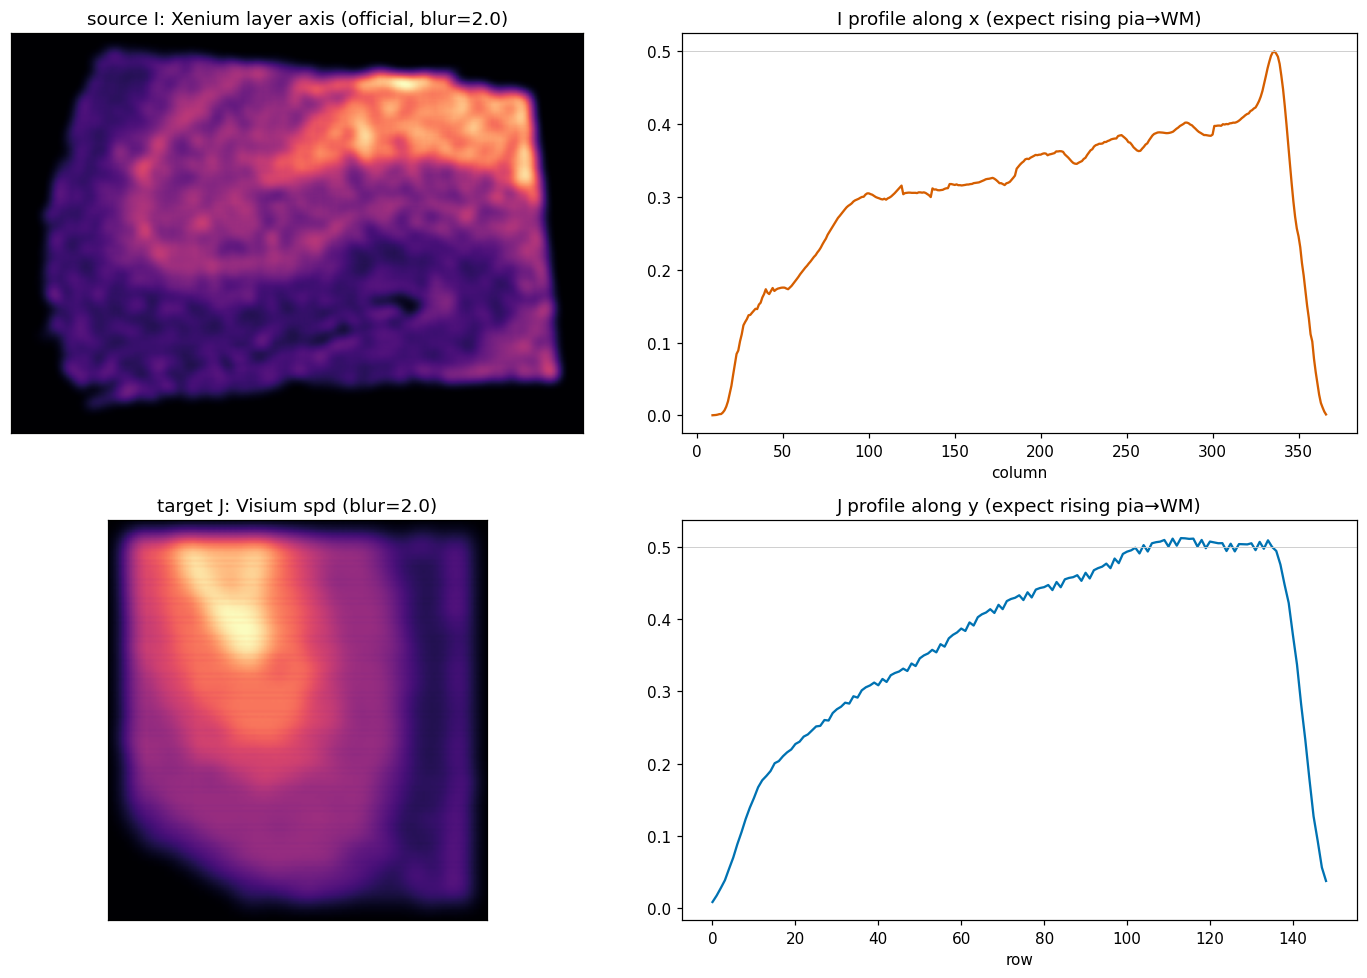

--- self-check ---
  [PASS] I profile mostly rising
  [PASS] J profile mostly rising
  [PASS] I no all-zero
  [PASS] J no all-zero
  rising frac: I=0.67  J=0.66
ALL PASS


In [20]:
# ============================================================
#  Cell 5 — rasterize layer signals (v2, Br8667)
#  source I : Xenium layer_axis (1=pia..7=WM, Lieber-official-backed)
#  target J : Visium spd ordinal (1=L1..7=WMtz)
#  Both must show a clean monotone gradient for LDDMM to match layers.
# ============================================================
def rasterize_signal(x, y, s, dx, blur):
    X, Y, img = STalign.rasterize_with_signal(x, y, s=np.asarray(s, float), dx=dx, blur=blur)
    return X, Y, STalign.normalize(np.repeat(img, 3, axis=0))

BLUR_SOURCE, BLUR_TARGET = 2.0, 2.0
XI, YI, I = rasterize_signal(xI, yI, layer_axis, DX_SOURCE, BLUR_SOURCE)
XJ, YJ, J = rasterize_signal(xJ, yJ, lab,        DX_TARGET, BLUR_TARGET)
print(f"I {I.shape}  grid {len(YI)}x{len(XI)}  dx={DX_SOURCE} µm")
print(f"J {J.shape}  grid {len(YJ)}x{len(XJ)}  dx={DX_TARGET} px")

# ---- verify gradient survived rasterization ----
def profile(img, axis):
    m = img[0].copy(); m[m == 0] = np.nan
    return np.nanmean(m, axis=axis)

fig, ax = plt.subplots(2, 2, figsize=(13, 9))
ax[0,0].imshow(I[0], cmap="magma", origin="lower")
ax[0,0].set_title(f"source I: Xenium layer axis (official, blur={BLUR_SOURCE})")
ax[0,1].plot(profile(I, 0), c="#D55E00")
ax[0,1].set_title("I profile along x (expect rising pia→WM)"); ax[0,1].set_xlabel("column")
ax[1,0].imshow(J[0], cmap="magma", origin="lower")
ax[1,0].set_title(f"target J: Visium spd (blur={BLUR_TARGET})")
ax[1,1].plot(profile(J, 1), c="#0072B2")
ax[1,1].set_title("J profile along y (expect rising pia→WM)"); ax[1,1].set_xlabel("row")
for a in (ax[0,0], ax[1,0]): a.set_xticks([]); a.set_yticks([])
for a in (ax[0,1], ax[1,1]): a.axhline(0.5, c="#ccc", lw=.6)
plt.tight_layout(); plt.show()

# ---- self-check: both profiles must be monotone-ish (rising) ----
def rising_frac(p):
    p = p[~np.isnan(p)]; return (np.diff(p) > 0).mean()
ri, rj = rising_frac(profile(I, 0)), rising_frac(profile(J, 1))
chk = {
    "I profile mostly rising": ri > 0.6,
    "J profile mostly rising": rj > 0.6,
    "I no all-zero":           I[0].max() > 0,
    "J no all-zero":           J[0].max() > 0,
}
print("--- self-check ---")
for k, v in chk.items(): print(f"  [{'PASS' if v else 'CHECK'}] {k}")
print(f"  rising frac: I={ri:.2f}  J={rj:.2f}")
print("ALL PASS" if all(chk.values()) else ">>> some CHECK <<<")


===== mirror=False =====
matched (WM>0.85): 75.8%  mean WM 0.747

===== mirror=True =====
matched (WM>0.85): 16.6%  mean WM 0.385

>>> chosen mirror=False | matched 75.8% (other 16.6%) <<<
--- self-check ---
  [PASS] one mirror clearly wins
  [PASS] winner matched > 50%
ALL PASS


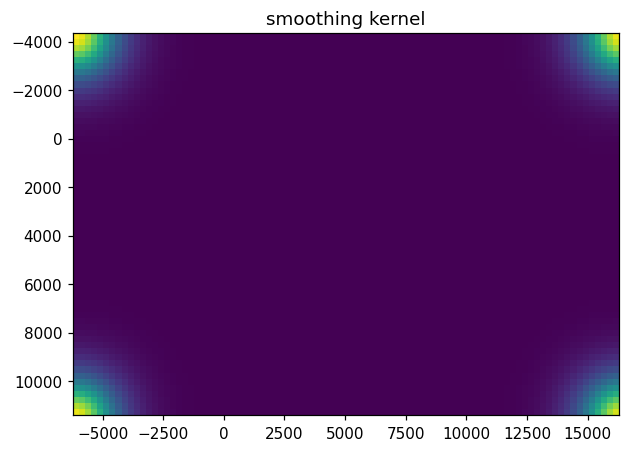

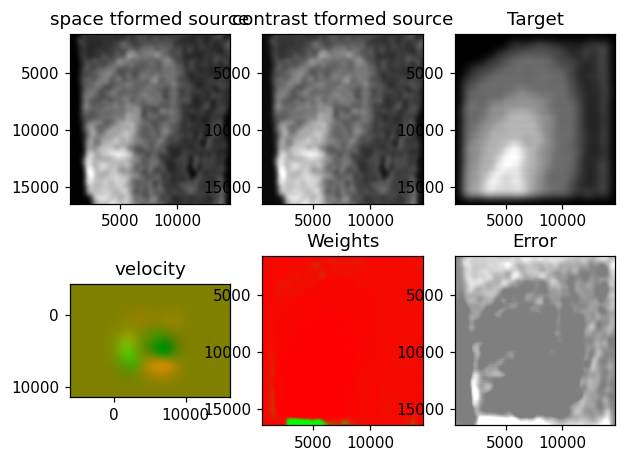

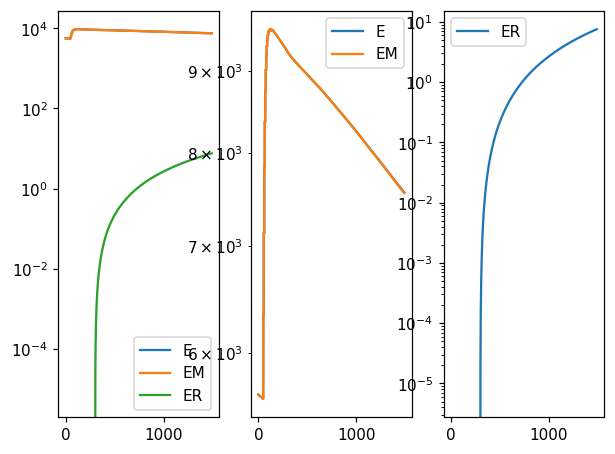

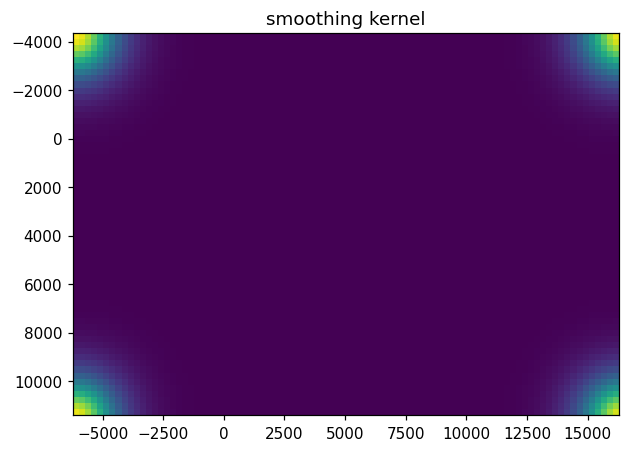

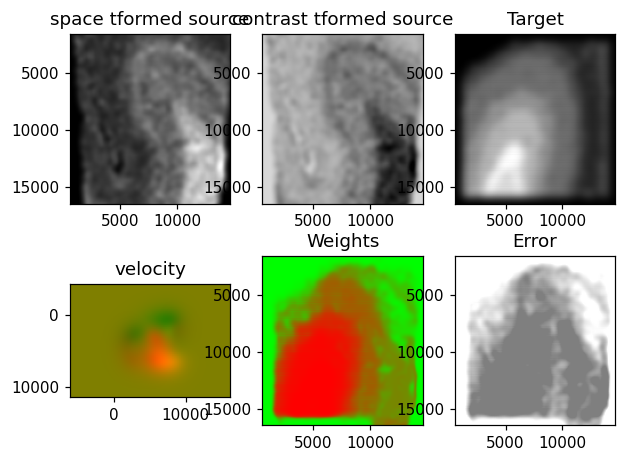

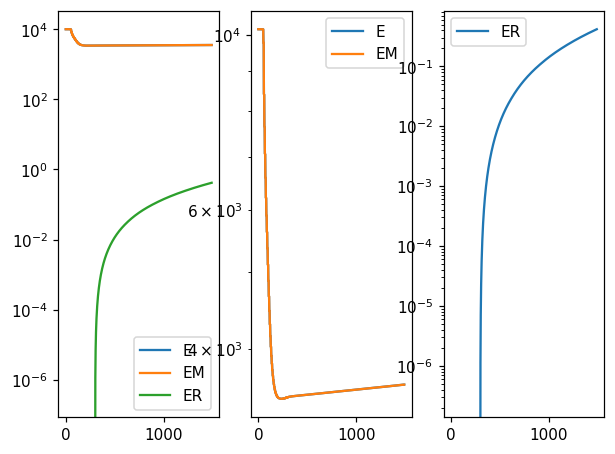

In [21]:
# ============================================================
#  Cell 6 — run LDDMM from both mirrors, decide by matched fraction
#  Uses official-layer-backed rasters (Cell 5). Mirror was degenerate
#  by IoU, so matched fraction is the deciding criterion.
# ============================================================
LDDMM_KW = dict(niter=1500, diffeo_start=300,
                sigmaM=0.3, sigmaB=0.3, sigmaA=0.3,
                epL=1e-8, epT=2e-1, epV=3e1,
                muB=torch.tensor([0., 0., 0.], device=device), device=device)

runs = {}
for m in (False, True):
    print(f"\n===== mirror={m} =====")
    A_try = torch.tensor(cands[m][0], dtype=DTYPE, device=device)
    out = STalign.LDDMM([YI, XI], I, [YJ, XJ], J, A=A_try, **LDDMM_KW)
    tp = STalign.transform_points_source_to_target(out["xv"], out["v"], out["A"],
                                                   np.stack([yI, xI], 1))
    tp = tp.cpu() if tp.is_cuda else tp
    w = STalign.interp([YJ, XJ], out["WM"][None].float(),
                       tp[None].permute(-1, 0, 1).float())
    w = (w.cpu() if w.is_cuda else w)[0, 0].numpy()
    runs[m] = dict(out=out, tp=tp.numpy(), wm=w)
    print(f"matched (WM>{MATCH_THRESH}): {(w>MATCH_THRESH).mean()*100:.1f}%  mean WM {w.mean():.3f}")

best = max(runs, key=lambda m: (runs[m]["wm"] > MATCH_THRESH).mean())
fr = {m: (runs[m]["wm"] > MATCH_THRESH).mean() for m in runs}
print(f"\n>>> chosen mirror={best} | matched {fr[best]*100:.1f}% "
      f"(other {fr[not best]*100:.1f}%) <<<")

chk = {
    "one mirror clearly wins": abs(fr[True]-fr[False]) > 0.15,
    "winner matched > 50%":    fr[best] > 0.50,
}
print("--- self-check ---")
for k, v in chk.items(): print(f"  [{'PASS' if v else 'CHECK'}] {k}")
print("ALL PASS" if all(chk.values()) else ">>> some CHECK <<<")

aligned 68974 cells | matched: 52298 (75.8%)
layer agreement (Xenium Lieber vs landed Visium spd):
  exact 19.0% | within-1-layer 72.2% | Spearman 0.581


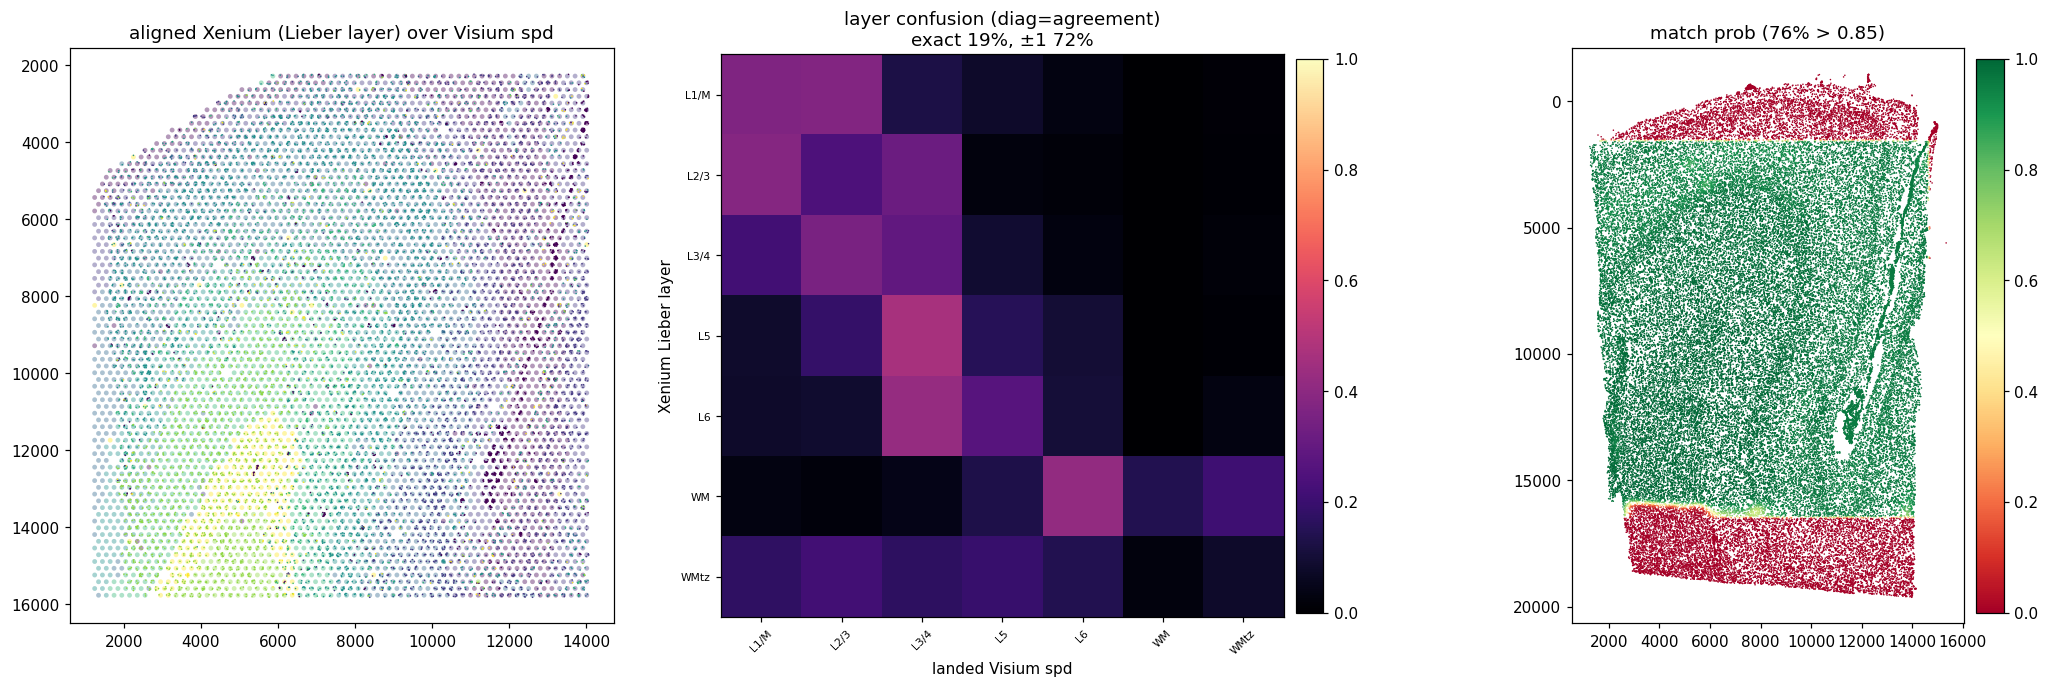

--- self-check ---
  [PASS] layer Spearman > 0.4
  [PASS] within-1-layer > 60%
  [PASS] matched > 50%
ALL PASS


In [22]:
# ============================================================
#  Cell 7 — apply transform, QC with OFFICIAL layer labels (v2)
#  mirror=False (75.8% vs 16.6%). Now that each Xenium cell carries a
#  Lieber layer label independent of Visium, we validate alignment by
#  layer agreement — not circular, unlike Visium-derived labels.
# ============================================================
MIRROR = best
out, tp, wm = runs[MIRROR]["out"], runs[MIRROR]["tp"], runs[MIRROR]["wm"]
xI_t, yI_t = tp[:, 1], tp[:, 0]
adata.obs["match_prob"] = wm
adata.obsm["aligned"]   = np.c_[xI_t, yI_t]
keep = wm > MATCH_THRESH
print(f"aligned {adata.n_obs} cells | matched: {keep.sum()} ({keep.mean()*100:.1f}%)")

# ---- for each matched Xenium cell: nearest Visium spot's spd layer ----
kd = cKDTree(np.c_[xJ, yJ]); d, j = kd.query(np.c_[xI_t, yI_t])
in_spot = (d <= SPOT_R_PX) & keep & adata.obs["layer"].notna().values
vis_spd = vadata.obs["spd_label"].map({d_: i for i, d_ in enumerate(SPD_ORDER)}).to_numpy()

# Lieber Xenium layer -> same ordinal scale as Visium spd
XLAYER2ORD = {"L1/M":0, "L2/3":1, "L3/4":2, "L5":3, "L6":4, "WM":5, "WMtz":6}
xen_lay_ord = adata.obs["layer"].map(XLAYER2ORD).to_numpy()

xo = xen_lay_ord[in_spot].astype(int)          # Xenium cell's own Lieber layer
vo = vis_spd[j[in_spot]].astype(int)           # the Visium spot it landed on
rho = spearmanr(xo, vo).statistic
same = (xo == vo).mean()
adj  = (np.abs(xo - vo) <= 1).mean()
print(f"layer agreement (Xenium Lieber vs landed Visium spd):")
print(f"  exact {same*100:.1f}% | within-1-layer {adj*100:.1f}% | Spearman {rho:.3f}")

# ---- figures ----
fig, ax = plt.subplots(1, 3, figsize=(19, 6))
LAY = ["L1/M","L2/3","L3/4","L5","L6","WM","WMtz"]

# (a) aligned Xenium coloured by its OWN Lieber layer, over Visium spd
p = ax[0].scatter(xJ, yJ, s=10, c=vis_spd, cmap="viridis", alpha=.4, linewidths=0)
ax[0].scatter(xI_t[in_spot], yI_t[in_spot], s=1, c=xo, cmap="viridis", linewidths=0, vmin=0, vmax=6)
ax[0].set_title("aligned Xenium (Lieber layer) over Visium spd")

# (b) confusion matrix Xenium-layer x Visium-spd
from numpy import add
C = np.zeros((7, 7))
np.add.at(C, (xo, vo), 1)
Cn = C / C.sum(1, keepdims=True).clip(1)
im = ax[1].imshow(Cn, cmap="magma", vmin=0, vmax=1)
ax[1].set_xticks(range(7)); ax[1].set_xticklabels(LAY, rotation=45, fontsize=7)
ax[1].set_yticks(range(7)); ax[1].set_yticklabels(LAY, fontsize=7)
ax[1].set_xlabel("landed Visium spd"); ax[1].set_ylabel("Xenium Lieber layer")
ax[1].set_title(f"layer confusion (diag=agreement)\nexact {same*100:.0f}%, ±1 {adj*100:.0f}%")
plt.colorbar(im, ax=ax[1], fraction=.046, pad=.02)

# (c) match probability
p = ax[2].scatter(xI_t, yI_t, s=1, c=wm, cmap="RdYlGn", vmin=0, vmax=1, linewidths=0)
ax[2].set_title(f"match prob ({keep.mean()*100:.0f}% > {MATCH_THRESH})")
plt.colorbar(p, ax=ax[2], fraction=.046, pad=.02)

for a in (ax[0], ax[2]): a.set_aspect("equal"); a.invert_yaxis()
plt.tight_layout(); plt.show()

# ---- self-check ----
chk = {
    "layer Spearman > 0.4":  rho > 0.4,
    "within-1-layer > 60%":  adj > 0.60,
    "matched > 50%":         keep.mean() > 0.50,
}
print("--- self-check ---")
for k, v in chk.items(): print(f"  [{'PASS' if v else 'CHECK'}] {k}")
print("ALL PASS" if all(chk.values()) else ">>> some CHECK <<<")

In [23]:
# ============================================================
#  Cell 10 — persist aligned Xenium + Visium with annotations (v2)
# ============================================================
adata.obs["match_prob"] = wm
adata.obsm["aligned"]   = np.c_[xI_t, yI_t]

# which Visium spot each aligned cell falls in (imputation pairing key)
kd = cKDTree(np.c_[xJ, yJ]); d, j = kd.query(np.c_[xI_t, yI_t])
in_spot = d <= SPOT_R_PX
adata.obs["visium_spot"] = np.where(in_spot, np.array(vadata.obs_names)[j.clip(0)], None)

adata.uns["alignment"] = dict(
    sample=SAMPLE, target_dx=str(dx), mirror=bool(MIRROR),
    px_per_um=float(PX_PER_UM), rotation_deg=90.0,
    matched_frac=float(keep.mean()), match_thresh=MATCH_THRESH,
    spot_radius_px=float(SPOT_R_PX),
    layer_exact=float(same), layer_within1=float(adj), layer_spearman=float(rho),
    annotation_source="LieberInstitute/spatialDLPFC_SCZ_XENIUM devel",
    annotation_coverage=float(adata.obs["layer"].notna().mean()),
    marker_axis_rho=0.857)

adata.write(f"{OUT}/{SAMPLE}_xenium_aligned_annotated.h5ad")
vadata.write(f"{OUT}/{SAMPLE}_visium.h5ad")
print(f"written -> {OUT}/")
print(f"  {SAMPLE}_xenium_aligned_annotated.h5ad : {adata.n_obs} cells")
print(f"  obs: layer, cell_type, banksy_clust, spd, match_prob, visium_spot, orig_row")
print(f"  obsm: spatial (µm), aligned (Visium px)")
print(f"  matched {keep.mean()*100:.0f}% | annotated {adata.obs['layer'].notna().mean()*100:.0f}% "
      f"| in-spot {in_spot.mean()*100:.0f}%")

written -> /home/yf23c/Guo_xenium/stalign_out/Br8667/
  Br8667_xenium_aligned_annotated.h5ad : 68974 cells
  obs: layer, cell_type, banksy_clust, spd, match_prob, visium_spot, orig_row
  obsm: spatial (µm), aligned (Visium px)
  matched 76% | annotated 96% | in-spot 18%


=== GM-layer marker screen (Visium Moran vs alignment Spearman) ===
  RORB     Moran=+0.318  Spearman=+0.124  meanExpr=2.04
  CUX2     Moran=+0.205  Spearman=+0.171  meanExpr=0.66
  LAMP5    Moran=+0.195  Spearman=+0.193  meanExpr=1.16
  CCK      Moran=+0.435  Spearman=+0.087  meanExpr=4.39
  PVALB    Moran=+0.235  Spearman=+0.087  meanExpr=1.02
  SST      Moran=+0.065  Spearman=-0.033  meanExpr=1.41
  -> GM example: CCK

=== layer-agreement vs permutation baseline ===
  exact:  observed 19%  | random 13±0.3%
  ±1:     observed 72%  | random 46±0.4%
  ±1 lift over random: 63.2 SD


/tmp/ipykernel_276150/781339023.py:149: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


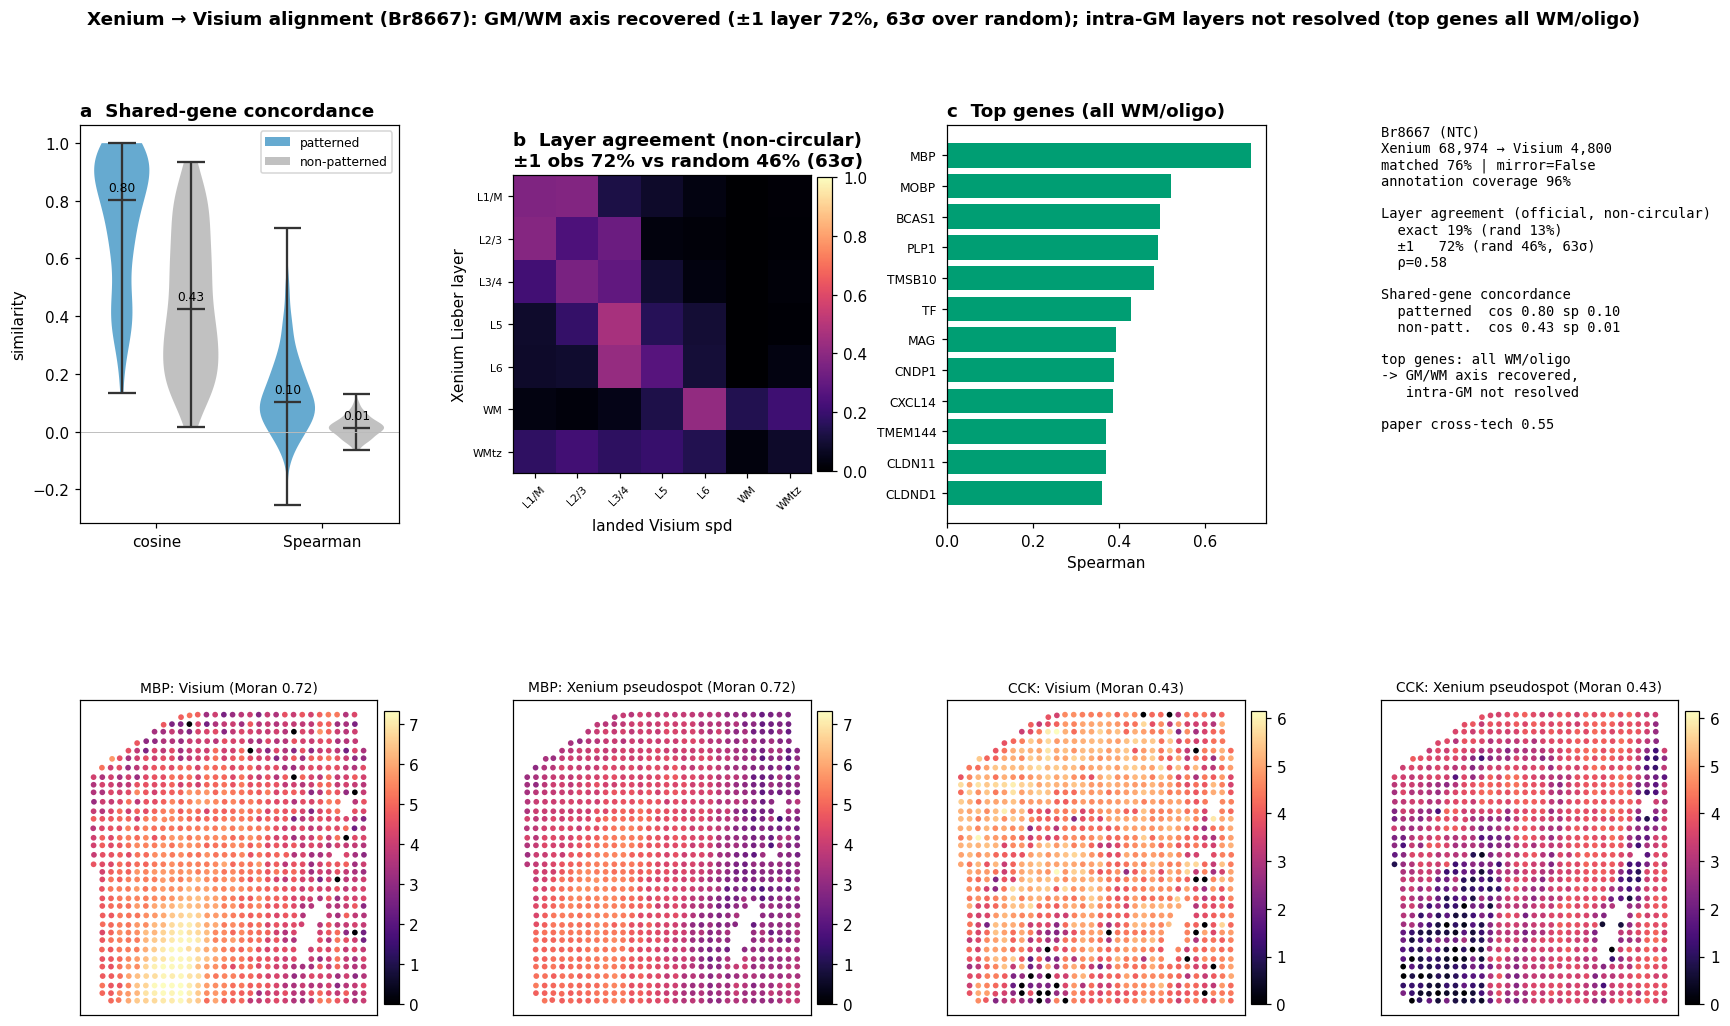


saved -> /home/yf23c/Guo_xenium/stalign_out/Br8667/fig_alignment_Br8667.png/pdf
WM marker: MBP (ρ=0.71) | GM marker: CCK (ρ=0.09, Moran=0.43)


In [25]:
# ============================================================
#  Cell 9 — alignment summary figure (v2, Br8667) — CORRECTED
#  Fixes: paired spatial maps share a colour scale; GM marker chosen
#  by (high Moran, low Spearman) = patterned-but-unaligned; ±1-layer
#  reported against a permutation baseline; title states the real
#  conclusion (GM/WM axis recovered, intra-GM limited).
#  Needs Cell 8 outputs (Pn,Vn,cxy,csim,ssim,moran,pat,res) and
#  Cell 7 outputs (Cn,same,adj,rho,xo,vo). Recomputes concordance if absent.
# ============================================================

# ---- ensure concordance quantities exist ----
if "res" not in dir():
    keepc = adata.obs["match_prob"].values > MATCH_THRESH
    Xk = adata.X[keepc]; Xk = Xk.toarray() if hasattr(Xk,"toarray") else np.asarray(Xk)
    xa, ya = xI_t[keepc], yI_t[keepc]
    g_px = GRID_UM * PX_PER_UM
    gid = lambda x,y: (np.floor((x-xJ.min())/g_px).astype(int)*100000 +
                       np.floor((y-yJ.min())/g_px).astype(int))
    gx, gv = gid(xa,ya), gid(xJ,yJ)
    common = np.intersect1d(np.unique(gx), np.unique(gv))
    Vc = vadata.X; Vc = Vc.toarray() if hasattr(Vc,"toarray") else np.asarray(Vc)
    xi_g=[adata.var_names.get_loc(g) for g in shared]; vi_g=[vadata.var_names.get_loc(g) for g in shared]
    def agg(M,gg,cols):
        o=np.zeros((len(common),len(cols)))
        for k,c in enumerate(common):
            m=gg==c
            if m.any(): o[k]=M[np.ix_(m,cols)].sum(0)
        return o
    Pg,Vg = agg(Xk,gx,xi_g), agg(Vc,gv,vi_g)
    nx=np.array([(gx==c).sum() for c in common]); ns=np.array([(gv==c).sum() for c in common])
    ok=(nx>=10)&(ns>=3)
    cxy=np.array([[xJ[gv==c].mean(),yJ[gv==c].mean()] for c in common[ok]])
    cpmlog=lambda M:(lambda L:np.log1p(M/np.where(L==0,1,L)*1e4))(M.sum(1,keepdims=True))
    Pn,Vn=cpmlog(Pg[ok]),cpmlog(Vg[ok])
    def mI(v,xy,k=6):
        nb=cKDTree(xy).query(xy,k=k+1)[1][:,1:]; z=v-v.mean(); d=(z**2).sum()
        return 0. if d==0 else (z*z[nb].mean(1)).sum()/d
    moran=np.array([mI(Vn[:,jj],cxy) for jj in range(len(shared))]); pat=moran>0.10
    cos=lambda a,b:(a@b/(np.linalg.norm(a)*np.linalg.norm(b))) if a.any() and b.any() else np.nan
    csim=np.array([cos(Pn[:,jj],Vn[:,jj]) for jj in range(len(shared))])
    ssim=np.array([spearmanr(Pn[:,jj],Vn[:,jj]).statistic
                   if Pn[:,jj].std() and Vn[:,jj].std() else np.nan for jj in range(len(shared))])
    res=pd.DataFrame({"gene":shared,"moran":moran,"cosine":csim,"spearman":ssim,
                      "patterned":pat}).sort_values("spearman",ascending=False)

# ============================================================
#  Diagnostics printed before the figure
# ============================================================
# (1) GM-layer marker screen: which are patterned in Visium but not recovered?
print("=== GM-layer marker screen (Visium Moran vs alignment Spearman) ===")
gm_cand = ["RORB","CUX2","FEZF2","TLE4","CBLN2","LAMP5","CCK","PVALB","SST","CUX1","POU3F2"]
gm_tbl = []
for g in gm_cand:
    if g in shared:
        j = shared.index(g)
        gm_tbl.append((g, moran[j], ssim[j], Vn[:,j].mean()))
        print(f"  {g:8s} Moran={moran[j]:+.3f}  Spearman={ssim[j]:+.3f}  meanExpr={Vn[:,j].mean():.2f}")
gm_pat = [t for t in gm_tbl if t[1] > 0.15]
gm = (min(gm_pat, key=lambda t: t[2])[0] if gm_pat
      else (max(gm_tbl, key=lambda t: t[1])[0] if gm_tbl else res.iloc[0]["gene"]))
print(f"  -> GM example: {gm}")

# (2) permutation baseline for the ±1-layer metric
rng = np.random.default_rng(0)
base_adj = np.array([(np.abs(rng.permutation(xo) - vo) <= 1).mean() for _ in range(200)])
base_exact = np.array([(rng.permutation(xo) == vo).mean() for _ in range(200)])
print(f"\n=== layer-agreement vs permutation baseline ===")
print(f"  exact:  observed {same*100:.0f}%  | random {base_exact.mean()*100:.0f}±{base_exact.std()*100:.1f}%")
print(f"  ±1:     observed {adj*100:.0f}%  | random {base_adj.mean()*100:.0f}±{base_adj.std()*100:.1f}%")
lift = (adj - base_adj.mean()) / base_adj.std()
print(f"  ±1 lift over random: {lift:.1f} SD")

# ============================================================
#  Figure
# ============================================================
OKB={"pat":"#0072B2","non":"#999999","wm":"#009E73","gm":"#D55E00"}
LAY=["L1/M","L2/3","L3/4","L5","L6","WM","WMtz"]

fig=plt.figure(figsize=(19,11)); gs=fig.add_gridspec(2,4,hspace=.34,wspace=.36)

# (a) concordance violins
axA=fig.add_subplot(gs[0,0]); cl=lambda a:a[~np.isnan(a)]
grp=[cl(csim[pat]),cl(csim[~pat]),cl(ssim[pat]),cl(ssim[~pat])]
pos=[1,2,3.4,4.4]; fc=[OKB["pat"],OKB["non"],OKB["pat"],OKB["non"]]
pv=axA.violinplot(grp,positions=pos,showmedians=True,widths=.8)
for pc,c in zip(pv["bodies"],fc): pc.set_facecolor(c); pc.set_alpha(.6)
for kk in ("cbars","cmins","cmaxes","cmedians"):
    if kk in pv: pv[kk].set_color("#333")
axA.set_xticks([1.5,3.9]); axA.set_xticklabels(["cosine","Spearman"])
axA.axhline(0,c="#bbb",lw=.6); axA.set_ylabel("similarity")
axA.set_title("a  Shared-gene concordance",fontweight="bold",loc="left")
for p,g in zip(pos,grp): axA.text(p,np.median(g)+.03,f"{np.median(g):.2f}",ha="center",fontsize=8)
axA.legend(handles=[plt.matplotlib.patches.Patch(fc=OKB["pat"],alpha=.6,label="patterned"),
                    plt.matplotlib.patches.Patch(fc=OKB["non"],alpha=.6,label="non-patterned")],
           fontsize=8,loc="upper right")

# (b) official-layer confusion + baseline in title
axB=fig.add_subplot(gs[0,1])
im=axB.imshow(Cn,cmap="magma",vmin=0,vmax=1)
axB.set_xticks(range(7)); axB.set_xticklabels(LAY,rotation=45,fontsize=7)
axB.set_yticks(range(7)); axB.set_yticklabels(LAY,fontsize=7)
axB.set_xlabel("landed Visium spd"); axB.set_ylabel("Xenium Lieber layer")
axB.set_title(f"b  Layer agreement (non-circular)\n"
              f"±1 obs {adj*100:.0f}% vs random {base_adj.mean()*100:.0f}% ({lift:.0f}σ)",
              fontweight="bold",loc="left")
plt.colorbar(im,ax=axB,fraction=.046,pad=.02)

# (c) top genes
axC=fig.add_subplot(gs[0,2]); tb=res.head(12).iloc[::-1]
axC.barh(range(len(tb)),tb["spearman"],
         color=[OKB["wm"] if p else OKB["non"] for p in tb["patterned"]])
axC.set_yticks(range(len(tb))); axC.set_yticklabels(tb["gene"],fontsize=8)
axC.set_xlabel("Spearman"); axC.set_title("c  Top genes (all WM/oligo)",fontweight="bold",loc="left")

# (d) summary
axD=fig.add_subplot(gs[0,3]); axD.axis("off")
txt=(f"Br8667 (NTC)\nXenium {adata.n_obs:,} → Visium {vadata.n_obs:,}\n"
     f"matched {keep.mean()*100:.0f}% | mirror={MIRROR}\n"
     f"annotation coverage {adata.obs['layer'].notna().mean()*100:.0f}%\n\n"
     f"Layer agreement (official, non-circular)\n"
     f"  exact {same*100:.0f}% (rand {base_exact.mean()*100:.0f}%)\n"
     f"  ±1   {adj*100:.0f}% (rand {base_adj.mean()*100:.0f}%, {lift:.0f}σ)\n"
     f"  ρ={rho:.2f}\n\n"
     f"Shared-gene concordance\n"
     f"  patterned  cos {np.nanmedian(csim[pat]):.2f} sp {np.nanmedian(ssim[pat]):.2f}\n"
     f"  non-patt.  cos {np.nanmedian(csim[~pat]):.2f} sp {np.nanmedian(ssim[~pat]):.2f}\n\n"
     f"top genes: all WM/oligo\n"
     f"-> GM/WM axis recovered,\n   intra-GM not resolved\n\n"
     f"paper cross-tech 0.55")
axD.text(0,1,txt,va="top",ha="left",fontsize=9,family="monospace")

# (e-h) paired spatial maps with SHARED colour scale
def pair(av,ax_,gene,cmap="magma"):
    jx=shared.index(gene)
    vlo=min(Vn[:,jx].min(),Pn[:,jx].min()); vhi=max(Vn[:,jx].max(),Pn[:,jx].max())
    for a,vals,tag in [(av,Vn[:,jx],"Visium"),(ax_,Pn[:,jx],"Xenium pseudospot")]:
        p=a.scatter(cxy[:,0],cxy[:,1],c=vals,s=14,cmap=cmap,vmin=vlo,vmax=vhi,linewidths=0)
        a.set_title(f"{gene}: {tag} (Moran {moran[jx]:.2f})",fontsize=9)
        a.set_aspect("equal"); a.invert_yaxis(); a.set_xticks([]); a.set_yticks([])
        plt.colorbar(p,ax=a,fraction=.046,pad=.02)

pair(fig.add_subplot(gs[1,0]),fig.add_subplot(gs[1,1]),"MBP")      # WM: aligns
pair(fig.add_subplot(gs[1,2]),fig.add_subplot(gs[1,3]),gm)         # GM: limited

fig.suptitle("Xenium → Visium alignment (Br8667): GM/WM axis recovered "
             f"(±1 layer {adj*100:.0f}%, {lift:.0f}σ over random); "
             "intra-GM layers not resolved (top genes all WM/oligo)",
             fontsize=12,fontweight="bold",y=.975)
plt.tight_layout()
for ext in ("png","pdf"):
    fig.savefig(f"{OUT}/fig_alignment_{SAMPLE}.{ext}",
                dpi=600 if ext=="png" else None,bbox_inches="tight")
plt.show()
print(f"\nsaved -> {OUT}/fig_alignment_{SAMPLE}.png/pdf")
print(f"WM marker: MBP (ρ={res.set_index('gene').loc['MBP','spearman']:.2f}) | "
      f"GM marker: {gm} (ρ={res.set_index('gene').loc[gm,'spearman']:.2f}, "
      f"Moran={moran[shared.index(gm)]:.2f})")